# 04. Modelos tabulares

Este cuaderno entrena los modelos que usan atributos visuales globales de cada fotografia: el
predictor constante de referencia, una regresion lineal sobre el exceso de verde y un Random Forest
Regressor. Todos estiman la severidad del dano condicionada a sequia: se entrenan solo con los
registros DR del subconjunto de entrenamiento y, al evaluar, la regla del conjunto asigna 0 a los
diagnosticos distintos de DR. Los artefactos y resultados quedan en `data/procesado`, de donde los
leen la API y el cuaderno de comparacion.

## Entorno

In [1]:
import sys
from pathlib import Path


def raiz_proyecto():
    for candidato in [Path.cwd(), *Path.cwd().parents]:
        if (candidato / "src").is_dir():
            return candidato
    raise RuntimeError("No se encontro la raiz del proyecto")


RAIZ = raiz_proyecto()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

%matplotlib inline
import numpy as np
import pandas as pd
from sklearn.base import clone

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

from src import graficos
from src.conjunto import cargar_conjunto
from src.evaluacion import cargar_resultados, metricas
from src.modelos_tabulares import (
    ATRIBUTOS_BOSQUE,
    RandomForestMagnitud,
    ajustar_bosque,
    ejecutar_random_forest,
    ejecutar_referencia_constante,
    ejecutar_regresion_exceso_verde,
    historial_busqueda,
)
from src.particiones import campos_compartidos, entrenamiento_y_prueba, separar_por_temporada

graficos.aplicar_estilo()

## Conjunto de modelado

El conjunto de modelado une los metadatos aptos con los atributos de cada imagen y trae fijada la
particion entre entrenamiento y prueba, agrupada por campo con semilla fija. El ajuste de
hiperparametros solo ve el entrenamiento DR; la prueba se usa una sola vez, al guardar los
resultados de cada modelo.

In [2]:
conjunto = cargar_conjunto()
entrenamiento, prueba = entrenamiento_y_prueba(conjunto, solo_dr=True)

print(f"registros del conjunto: {len(conjunto)}")
print(f"DR de entrenamiento: {len(entrenamiento)} en {entrenamiento['id_campo'].nunique()} campos")
print(f"DR de prueba: {len(prueba)} en {prueba['id_campo'].nunique()} campos")

registros del conjunto: 23350
DR de entrenamiento: 3655 en 1453 campos
DR de prueba: 834 en 358 campos


## Entrenamiento de los modelos

Cada funcion entrena, guarda el artefacto en `data/procesado/modelos` y guarda los resultados de
prueba en `data/procesado/resultados`. El Random Forest busca 30 combinaciones de hiperparametros
con `RandomizedSearchCV`, validando con cinco pliegues agrupados por campo para que un mismo campo
nunca quede a ambos lados de la validacion. La combinacion se elige por menor RMSE de validacion y
se reajusta con todo el entrenamiento DR. Su tiempo de entrenamiento incluye la busqueda completa y
ese reajuste.

In [3]:
rutas = [
    ejecutar_referencia_constante(conjunto),
    ejecutar_regresion_exceso_verde(conjunto),
    ejecutar_random_forest(conjunto, n_iter=30),
]
for ruta in rutas:
    print(ruta.relative_to(RAIZ))

data/procesado/resultados/constante.json
data/procesado/resultados/regresion_exceso_verde.json
data/procesado/resultados/random_forest.json


In [4]:
resultados = {modelo_id: cargar_resultados(modelo_id) for modelo_id in ("constante", "regresion_exceso_verde", "random_forest")}
pd.DataFrame(
    [
        {
            "modelo": modelo_id,
            "hiperparametros": r.hiperparametros,
            "entrenamiento_s": round(r.tiempo_entrenamiento_s, 3),
            "inferencia_ms": round(r.tiempo_inferencia_ms, 4),
        }
        for modelo_id, r in resultados.items()
    ]
)

,modelo,hiperparametros,entrenamiento_s,inferencia_ms
0,constante,"{'valor': 41.1765, 'subconjunto': 'DR'}",0.000,0.0000
1,regresion_exceso_verde,"{'pendiente': -146.7926, 'intercepto': 54.4628}",0.056,0.0012
2,random_forest,"{'n_estimators': 200, 'min_samples_leaf': 10, ...",23.153,0.0219


La regresion tiene pendiente negativa: un aumento de 0.1 en el exceso de verde reduce la magnitud
estimada en unos 14.7 puntos, coherente con la perdida de verdor que causa la sequia. El Random
Forest tarda menos de un minuto, incluida la busqueda de 30 combinaciones con cinco pliegues. Su
inferencia por registro queda por debajo de una decima de milisegundo porque parte de los atributos
ya calculados.

## Ajuste de hiperparametros del Random Forest

Cada fila es una combinacion probada, con el RMSE y el MAE medios de validacion sobre la magnitud
en escala de 0 a 100. La fila marcada como elegida es la que se reajusto y se evaluo en la prueba.

In [5]:
resultados_rf = resultados["random_forest"]
historial = pd.DataFrame(
    [
        {**paso.parametros, "rmse_validacion": paso.rmse_validacion, "mae_validacion": paso.mae_validacion, "elegido": paso.elegido}
        for paso in resultados_rf.historial_ajuste
    ]
).sort_values("rmse_validacion", ignore_index=True)
historial.round(3)

,n_estimators,min_samples_leaf,max_features,max_depth,rmse_validacion,mae_validacion,elegido
0,200,10,sqrt,10.0,20.646,16.428,True
1,300,20,0.5,NaN,20.669,16.431,False
2,100,20,0.5,20.0,20.670,16.435,False
3,200,10,0.5,10.0,20.680,16.405,False
4,200,5,sqrt,NaN,20.710,16.452,False
5,500,1,sqrt,10.0,20.711,16.467,False
6,200,50,0.5,NaN,20.737,16.591,False
7,100,5,sqrt,20.0,20.739,16.459,False
8,300,50,0.5,NaN,20.739,16.589,False
9,200,5,0.5,NaN,20.742,16.436,False


Las 30 combinaciones quedan entre 20.65 y 21.04 de RMSE de validacion, una diferencia de 0.4
puntos, asi que el error depende poco de los hiperparametros. Entre las mejores predominan hojas de
10 a 20 registros y una fraccion de los atributos en cada division, que suavizan las predicciones.
Las peores limitan la profundidad a 5 o combinan hojas de un solo registro con todos los atributos.
La combinacion elegida usa 200 arboles, profundidad maxima de 10, hojas de al menos 10 registros y
la raiz cuadrada del numero de atributos en cada division.

## Atributos de dispositivo

El analisis de imagenes mostro que `megapixeles` y `nitidez` cambian con la temporada: la resolucion
media pasa de 0.49 megapixeles en las primeras temporadas a 3.39 en SR2021. Estos atributos pueden
describir el telefono o la temporada mas que el dano, por lo que el modelo final los excluye. Para
cuantificar esa decision se repite la busqueda agregandolos y se comparan ambas variantes solo con
la validacion por campo, sin tocar la prueba ni guardar resultados.

In [6]:
elegido = next(paso for paso in resultados_rf.historial_ajuste if paso.elegido)
busqueda_dispositivo = ajustar_bosque(entrenamiento, ATRIBUTOS_BOSQUE + ("megapixeles", "nitidez"), n_iter=30)
elegido_dispositivo = next(paso for paso in historial_busqueda(busqueda_dispositivo) if paso["elegido"])

pd.DataFrame(
    [
        {"variante": "sin megapixeles ni nitidez", "atributos": len(ATRIBUTOS_BOSQUE), "rmse_validacion": elegido.rmse_validacion, "mae_validacion": elegido.mae_validacion},
        {"variante": "con megapixeles y nitidez", "atributos": len(ATRIBUTOS_BOSQUE) + 2, "rmse_validacion": elegido_dispositivo["rmse_validacion"], "mae_validacion": elegido_dispositivo["mae_validacion"]},
    ]
).round(3)

,variante,atributos,rmse_validacion,mae_validacion
0,sin megapixeles ni nitidez,9,20.646,16.428
1,con megapixeles y nitidez,11,20.391,16.228


Agregar `megapixeles` y `nitidez` baja el RMSE de validacion de 20.65 a 20.39 y el MAE de 16.43 a
16.23. La mejora, de 0.26 puntos, es menor que la diferencia entre las combinaciones de la busqueda.
Ademas, la validacion por campo mezcla las cuatro temporadas, por lo que no permite distinguir si la
ganancia viene del dano o de reconocer la temporada por el telefono: SR2021 tiene fotografias de
mayor resolucion y una magnitud media menor que las temporadas anteriores. Por eso el modelo final
conserva los nueve atributos, sin `megapixeles` ni `nitidez`.

## Importancia de los atributos

La importancia de cada atributo es la reduccion media de impureza que aporta en los arboles del
modelo elegido, normalizada para que la suma sea 1.

,variable,importancia
0,exceso_verde,0.468
1,media_r,0.123
2,saturacion,0.085
3,media_g,0.082
4,brillo,0.057
5,media_b,0.055
6,prop_sobreexpuesta,0.046
7,contraste,0.044
8,prop_subexpuesta,0.041


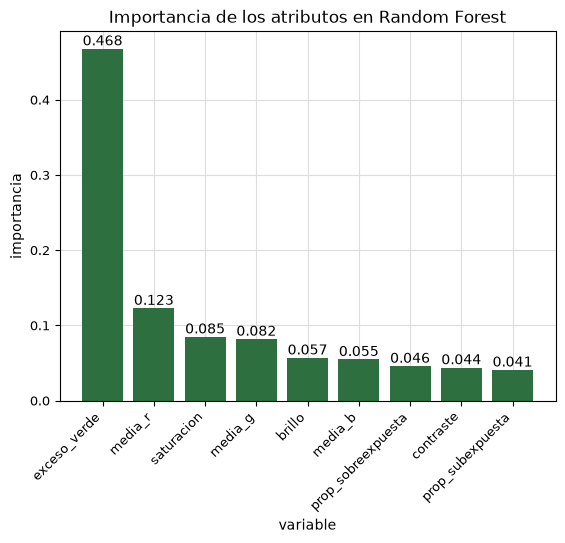

In [7]:
importancias = pd.DataFrame([i.model_dump() for i in resultados_rf.importancias])
importancias["importancia"] = importancias["importancia"].round(3)
fig = graficos.barras_frecuencia(importancias, "Importancia de los atributos en Random Forest", columna_valor="importancia")
for etiqueta in fig.axes[0].get_xticklabels():
    etiqueta.set(rotation=45, horizontalalignment="right")
graficos.guardar_figura(fig, "04_importancia_atributos")
importancias

El exceso de verde concentra 0.47 de la importancia, casi cuatro veces mas que el siguiente
atributo, la media del canal rojo (0.12). Coincide con el analisis exploratorio, donde fue el
atributo con mayor correlacion con la magnitud. El contraste y las proporciones de exposicion
aportan poco.

## Generalizacion temporal

La particion por campo mezcla las cuatro temporadas en ambos lados. Para medir la generalizacion
hacia una temporada nueva, dentro del entrenamiento DR se entrena el Random Forest con los
hiperparametros elegidos sobre las temporadas anteriores y se evalua en SR2021. Se usa solo el
subconjunto de entrenamiento para no gastar la prueba. Tambien se cuentan los campos que aparecen en
ambas partes, porque un campo compartido puede inflar el resultado.

In [8]:
anteriores, sr2021 = separar_por_temporada(entrenamiento)
elegido_rf = RandomForestMagnitud()
elegido_rf.cargar()
temporal = RandomForestMagnitud().entrenar(anteriores, clone(elegido_rf.estimador))
valores = metricas(sr2021["magnitud"], np.clip(temporal.predecir_lote(sr2021), 0, 100))
referencia = metricas(sr2021["magnitud"], np.full(len(sr2021), anteriores["magnitud"].mean()))
compartidos = campos_compartidos(anteriores, sr2021)

print(f"entrenamiento sin SR2021: {len(anteriores)} registros DR, magnitud media {anteriores['magnitud'].mean():.2f}")
print(f"evaluacion en SR2021: {len(sr2021)} registros DR en {sr2021['id_campo'].nunique()} campos, magnitud media {sr2021['magnitud'].mean():.2f}")
print(f"campos compartidos entre ambas partes: {len(compartidos)}")
print(f"registros de SR2021 en campos compartidos: {sr2021['id_campo'].isin(compartidos).mean():.1%}")
pd.DataFrame(
    [
        {"evaluacion": "random forest, validacion por campo con 5 pliegues", "rmse": elegido.rmse_validacion, "mae": elegido.mae_validacion},
        {"evaluacion": "random forest, temporal evaluado en SR2021", "rmse": valores["rmse"], "mae": valores["mae"]},
        {"evaluacion": "media de temporadas anteriores, evaluada en SR2021", "rmse": referencia["rmse"], "mae": referencia["mae"]},
    ]
).round(3)

entrenamiento sin SR2021: 2424 registros DR, magnitud media 43.30
evaluacion en SR2021: 1231 registros DR en 732 campos, magnitud media 36.99
campos compartidos entre ambas partes: 353
registros de SR2021 en campos compartidos: 53.0%


,evaluacion,rmse,mae
0,"random forest, validacion por campo con 5 plie...",20.646,16.428
1,"random forest, temporal evaluado en SR2021",20.526,16.019
2,"media de temporadas anteriores, evaluada en SR...",24.189,20.395


Entrenado con LR2020, SR2020 y LR2021, el Random Forest obtiene en SR2021 un RMSE de 20.53, muy
cercano al 20.65 de la validacion por campo, mientras que predecir la magnitud media de las
temporadas anteriores llega a 24.19. No se observa una caida de desempeno al cambiar de temporada,
aunque la magnitud media de SR2021 es seis puntos menor. El resultado es en parte optimista: 353 de
los 732 campos de SR2021 tambien aparecen en las temporadas anteriores y concentran el 53 % de sus
registros, de modo que el modelo ya vio fotografias de esos mismos campos.

## Cierre

Los tres modelos tabulares quedan entrenados, guardados y evaluados una sola vez sobre la prueba. El
Random Forest depende poco de sus hiperparametros y se apoya sobre todo en el exceso de verde, lo
que confirma que ese indice resume buena parte de la senal visual de la sequia, aunque no toda.
Excluir `megapixeles` y `nitidez` cuesta menos de 0.3 puntos de RMSE de validacion y evita que el
modelo aprenda la temporada a traves del telefono. La comparacion con la prueba, con el resto de los
modelos y con las redes convolucionales se realiza en el cuaderno 07.